# How wrong is Forward Euler, and when does it matter?

**Question:** The engine advances the SIR equations in quarter-day steps with the simplest scheme there is. By how much do its peak and its final size differ from the exact ones for the epidemic case, does that matter for the cases on file, and what would a better answer cost?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can write one Forward Euler step by hand and find it in the engine's first step, measure the engine's error against two exact references that share no code with it, read the order of the scheme from how the error shrinks with the step, and judge for which cases and which quantities a quarter-day step is accurate enough. You also see how to remove most of the error without a better integrator.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and the pipeline's modules, prints the versions and defines the reader of the cases' parameters.

In [1]:
# the tools, their versions, the pipeline's modules and the reader of the cases' parameters
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import peak_frac
from pipeline.model.sir import simulate
from pipeline.oracles import final_size

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Data

The parameters of the five cases of the example.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`, for the parameters only; every course shown here is computed by the engine.

## Method

Forward Euler moves a system $y' = f(y)$ forward by following its tangent for one step $\Delta t$: $y_{k+1} = y_k + \Delta t\, f(y_k)$. For the SIR system the tangent at a step says that $\beta S I \Delta t / N$ susceptible people become infected and $\gamma I \Delta t$ infected people recover, which is all the engine does (it also clips $S$ and $I$ at zero). The scheme is first order: halving $\Delta t$ halves the global error (Hairer, Norsett and Wanner, 1993). That is a claim about a limit, and this notebook measures it at the steps in use.

To measure an error you need the exact answer. Two quantities of the SIR system have one in closed form and independent of any integrator. The final size solves $1 - z = (1 - i_0) e^{-R_0 z}$ (Kermack and McKendrick, 1927; Miller, 2012), which `final_size` of `pipeline/oracles.py` finds by fixed-point iteration, and the infected fraction peaks at $1 - (1 + \ln R_0) / R_0$ when the initial infection vanishes, which `peak_frac` of `pipeline/model/baseline.py` evaluates. The analytic peak ignores the first 50 infected people, so it is off by a fraction of a percent; keep that in mind when reading the peak errors.

First one step by hand, on the epidemic case with $\Delta t = 0.25$ days. The new infections are $\beta (N - I_0) I_0 \Delta t / N$ and the new recoveries $\gamma I_0 \Delta t$. The cell computes the three compartments after one step in plain arithmetic and prints them next to the first step of `simulate`. If the description of the scheme above is right, the two lines agree.

In [2]:
# one Forward Euler step by hand on the epidemic case, next to the first step the engine takes
p = params_of("EX02_epidemic")
dt = 0.25
new_infections = p.beta / p.N * (p.N - p.I0) * p.I0 * dt
new_recoveries = p.gamma * p.I0 * dt
by_hand = [p.N - p.I0 - new_infections, p.I0 + new_infections - new_recoveries, new_recoveries]
engine = simulate(p, dt)
print("by hand  ", [round(v, 3) for v in by_hand])
print("engine ", [round(v[1], 3) for v in (engine.S, engine.I, engine.R)])

by hand   [99943.128, 54.372, 2.5]
engine  [99943.128, 54.372, 2.5]


The two lines are the same to three decimals: the engine is the textbook scheme and nothing else. Now the question of how far that scheme is from the truth. The next cell runs the engine on the epidemic case at five steps, from a whole day down to a sixteenth of a day, and compares each run with the two exact references. It prints the number of steps each run takes, which is the cost, next to the attack rate and the peak it produced.

In [3]:
# the engine at five step sizes on the epidemic case, against the exact final size and the analytic peak
p = params_of("EX02_epidemic")
steps = [1.0, 0.5, 0.25, 0.125, 0.0625]
exact_attack = final_size(p.beta / p.gamma, p.I0 / p.N)
exact_peak = peak_frac(p.beta / p.gamma) * p.N
attack_error = []
peak_error = []
for dt in steps:
    r = simulate(p, dt)
    attack_error.append(r.attack_rate - exact_attack)
    peak_error.append(r.peak_I / exact_peak - 1)
    print(f"dt = {dt:6.4f}  {len(r.t) - 1:5d} steps  attack rate {r.attack_rate:.6f}  peak {r.peak_I:7.0f}")
print(f"exact: attack rate {exact_attack:.6f}, peak {exact_peak:.0f}")

dt = 1.0000    160 steps  attack rate 0.933717  peak   28845
dt = 0.5000    320 steps  attack rate 0.926912  peak   27836
dt = 0.2500    640 steps  attack rate 0.923654  peak   27345
dt = 0.1250   1280 steps  attack rate 0.922060  peak   27107
dt = 0.0625   2560 steps  attack rate 0.921271  peak   26988
exact: attack rate 0.920487, peak 26851


The attack rate falls from 0.933717 at a one-day step toward the exact 0.920487 and does not get there; the peak falls from 28845 toward 26851 the same way, and the work grows in proportion, from 160 to 2560 steps. The next cell draws both errors against the step on logarithmic axes, with a line of slope one for comparison. A first-order scheme should run parallel to that line.

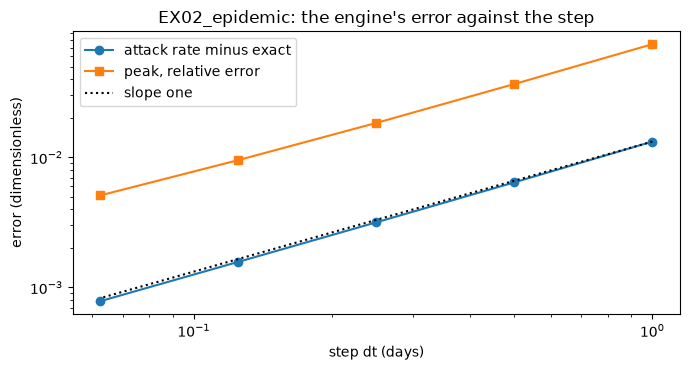

In [4]:
# draw the two errors against the step on log axes, with a line of slope one for comparison
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(steps, np.abs(attack_error), "o-", label="attack rate minus exact")
ax.loglog(steps, np.abs(peak_error), "s-", label="peak, relative error")
ax.loglog(steps, np.array(steps) * attack_error[0] / steps[0], "k:", label="slope one")
ax.set_xlabel("step dt (days)")
ax.set_ylabel("error (dimensionless)")
ax.set_title("EX02_epidemic: the engine's error against the step")
ax.legend()
fig.tight_layout()
plt.show()

On log axes both errors fall on straight lines parallel to the dotted line of slope one: every time the step is halved, the attack-rate error and the peak error are halved too, which is the signature of a first-order scheme. At the engine's own step of 0.25 days the attack rate is high by about 0.003 and the peak by 1.8 percent, so the peak is the more sensitive of the two. The figure does not say where along the course the error is made, which is what the reference run below shows.

What would it cost to bring the peak within a tenth of a percent? If the error keeps shrinking in proportion to the step, the step has to shrink by the same factor. The cell extrapolates from the error at 0.25 days and prints the step it implies and the work it multiplies.

In [5]:
# the step a peak within 0.1 percent would need, if the error keeps shrinking in proportion to the step
per_day = peak_error[2] / steps[2]
needed = 0.001 / per_day
print(f"now: dt = {steps[2]}, relative peak error {peak_error[2]:+.4f}, {p.days / steps[2]:.0f} steps")
steps_needed = p.days / needed
work = steps_needed / (p.days / steps[2])
print(f"needed: dt = {needed:.4f}, {steps_needed:.0f} steps, {work:.0f} times the work")

now: dt = 0.25, relative peak error +0.0184, 640 steps
needed: dt = 0.0136, 11783 steps, 18 times the work


A peak within 0.1 percent needs a step of about 0.0136 days and 11783 steps, 18 times the work of the engine's default. That is cheap here, where a run takes milliseconds, and would not be for a model that costs minutes per run. The analytic peak cannot show where the error comes from, so the next cell builds a reference course from a step 32 times finer than the engine's, 1/128 of a day, and subtracts it from the courses at one day and at a quarter of a day, point by point. To line the grids up the cell keeps every 32nd point of the fine run for the quarter-day course and every 128th for the one-day course.

In [6]:
# a reference course from a step 32 times finer than the engine's, and the error of two coarser courses along the way
reference = simulate(p, 1 / 128)
reference_i = np.array(reference.I)
errors = {}
for dt in (1.0, 0.25):
    course = simulate(p, dt)
    errors[dt] = (np.array(course.I) - reference_i[:: round(dt * 128)]) / p.N
    worst = int(errors[dt].argmax())
    print(f"dt = {dt:4.2f}  largest {errors[dt][worst]:+.4f} on day {course.t[worst]:.2f}", end="  ")
    print(f"smallest {errors[dt].min():+.4f}")

dt = 1.00  largest +0.0660 on day 29.00  smallest -0.0749
dt = 0.25  largest +0.0154 on day 27.75  smallest -0.0195


The next cell draws the error of the infected curve along the horizon, as a share of the population, for the two courses.

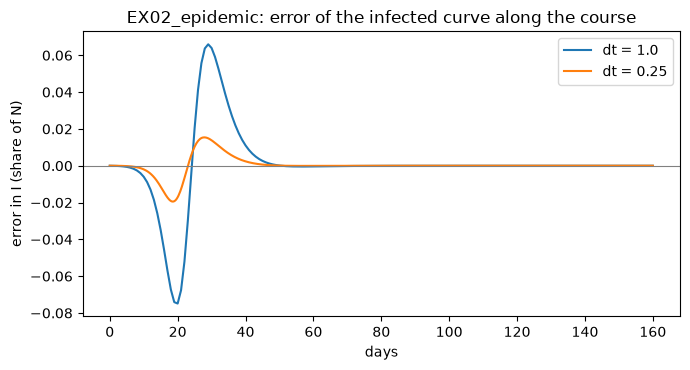

In [7]:
# draw the error of the infected curve along the horizon, as a share of the population
fig, ax = plt.subplots(figsize=(7, 3.8))
for dt, err in errors.items():
    ax.plot(np.arange(len(err)) * dt, err, label=f"dt = {dt}")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("days")
ax.set_ylabel("error in I (share of N)")
ax.set_title("EX02_epidemic: error of the infected curve along the course")
ax.legend()
fig.tight_layout()
plt.show()

The error of the infected curve has a signed shape: negative on the rising side and positive just after the peak, because the Euler hump arrives a little late and a little high. At the engine's step the largest error is 0.0154 of the population, on day 27.75, against 0.0660 at a one-day step, four times larger for a step four times larger. The error is greatest where the curve is steepest, as it must be for a scheme that follows the tangent. The figure does not contain the other four cases; the next cell does.

When does a quarter-day step matter? It depends on the case and on the quantity. The cell below runs every case that has infected people at the engine's step and at the fine step, and prints how much the engine's peak, the day of the peak and the attack rate move. The reference here is the fine run and not the analytic formulas, so the numbers differ slightly from the earlier ones: the fine run has its own error, about 0.06 percent in the peak.

In [8]:
# the error of the engine's own step on every case that has infected people, against the finer reference
print(f"{'case':18s} {'peak err':>10s} {'day shift':>12s} {'attack err':>12s}")
for case_id in CASES:
    q = params_of(case_id)
    if q.I0 == 0:
        continue
    fine = simulate(q, 1 / 128)
    own = simulate(q)
    d_peak = own.peak_I / fine.peak_I - 1
    d_day = own.t_peak - fine.t_peak
    d_attack = own.attack_rate - fine.attack_rate
    print(f"{case_id:18s} {d_peak:+10.4f} {d_day:+12.2f} {d_attack:+12.5f}")

case                 peak err    day shift   attack err
EX01_subcritical      +0.0000        +0.00     +0.00000
EX02_epidemic         +0.0172        +0.79     +0.00307
EX03_fast_burn        +0.0322        +0.53     +0.00070
EX04_slow_spread      +0.0038        +0.32     +0.00051


The fast burn has the largest peak error, 3.2 percent, and the slow spread the smallest, 0.4 percent: the faster the dynamics, the more of the course a quarter-day step skips. The peak arrives 0.3 to 0.8 days late in the outbreak cases. The attack rate is high by 0.003 at most, and the sub-critical case has no error at all because nothing happens in it. Against the bands the example's cases declare (`expect` in `pipeline/cases/example_case.py`), an attack rate between 0.90 and 0.95 for the epidemic, the step is harmless; for a decision that sizes capacity on the peak with a margin of a few percent, it is not.

Last, a way to improve the answer without touching the integrator. If the error is proportional to the step, three runs at $\Delta t$, $\Delta t / 2$ and $\Delta t / 4$ reveal the order from the ratio of their differences, and the last two runs extrapolate to a zero step: $2 x_{\Delta t/4} - x_{\Delta t/2}$ (Richardson extrapolation, see Hairer, Norsett and Wanner, 1993). The cell does this for the attack rate, which the exact final size lets us judge.

In [9]:
# estimate the order of the scheme from three runs at dt, dt / 2 and dt / 4, with no exact answer needed
attack = [simulate(p, dt).attack_rate for dt in (0.5, 0.25, 0.125)]
order = np.log2((attack[0] - attack[1]) / (attack[1] - attack[2]))
extrapolated = 2 * attack[2] - attack[1]
print(f"estimated order: {order:.2f}")
print(f"finest run {attack[2]:.6f}, extrapolated {extrapolated:.6f}, exact {exact_attack:.6f}")

estimated order: 1.03
finest run 0.922060, extrapolated 0.920465, exact 0.920487


## Results

**Answer:** At the engine's quarter-day step the epidemic case ends with an attack rate of 0.923654 against the exact 0.920487, and a peak of 27345 people against the analytic 26851, 1.8 percent high. Both errors halve when the step halves: the estimated order is 1.03. For the cases on file the peak error runs from 0.4 percent for the slow spread to 3.2 percent for the fast burn, the peak arrives up to 0.79 days late, and the attack rate is off by at most 0.003. A peak within 0.1 percent would need 11783 steps, 18 times the work, but extrapolating from the runs at 0.5, 0.25 and 0.125 days gives 0.920465 for the attack rate, within 0.00003 of the exact value, at the price of two cheap runs more.

So a quarter-day step is accurate enough for the final size and for dating the peak to within a day, and not for sizing the peak itself when the margin is a few percent. What the notebook does not show is the error of a higher-order scheme, which is the subject of notebook 03, and the error in cases with other parameters than the five on file; the fast burn suggests it grows with $\beta$.

## Summary

- The engine's step is the Forward Euler step: the hand calculation matches its first step.
- Its error is first order: halving the step halves the error of the attack rate and of the peak (order 1.03).
- At the default quarter-day step the peak is 1.8 percent high in the epidemic case and up to 3.2 percent in the fast burn; the attack rate is off by at most 0.003.
- Richardson extrapolation from three cheap runs removes most of the attack-rate error.
- Next: the same cases against a higher-order solver, in notebook 03 of this topic.

## References

- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine, the oracle and the baseline of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/oracles.py`, `pipeline/model/baseline.py`).